# 🏆 Decision Intelligence Capstone: Modelado Predictivo, Inferencia Causal y Sistemas de Decisión en Producción
**Cátedra:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026)  
**Institución:** Pontificia Universidad Católica Argentina (UCA) — Facultad de Ingeniería y Ciencias Agrarias  
**Profesor Titular:** Prof. Ivan Gonzalo Vilaboa  
**Integrantes y Roles Scrum:**
- 👑 **Project Lead & Scrum Master:** German y equipo
- ⚙ **Backend & Machine Learning / Causal Engineer:** Equipo EAyMR
- 🎨 **Frontend & UI/UX Engineer:** Equipo EAyMR
- 🔍 **QA & Validation Engineer:** Equipo EAyMR

---

## 🔬 FASE 1: Inferencia Estadística Clásica, Diagnósticos y ANOVA
En esta primera fase demostramos comprensión inferencial de los datos poblacionales y muestrales:
1. **Ingeniería Exploratoria y Caracterización de Distribuciones:** Análisis univariado y bivariado (KDE, boxplots, correlaciones de Pearson y Spearman).
2. **Mecanismos de Pérdida de Datos:** Clasificación formal de variables faltantes entre MCAR, MAR o MNAR mediante modelado logístico econométrico.
3. **Contrastes de Hipótesis Formales:** Formulación de $H_0$ frente a $H_1$, fijación de $\alpha = 0.05$, cálculo de $p$-valores exactos, intervalos de confianza del 95% y magnitud del efecto ($d$ de Cohen).
4. **Análisis de Varianza (ANOVA) de un Factor:** Evaluación del comportamiento de Shapiro-Wilk en muestras masivas ($N \ge 1.500$), diagnóstico de homocedasticidad con Levene, y remediación formal mediante **Welch's ANOVA** y comparaciones múltiples post-hoc.


In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import HuberRegressor

# Configuración gráfica y estética
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Entorno estadístico y econométrico inicializado exitosamente.")


Entorno estadístico y econométrico inicializado exitosamente.


### 1.1 Ingesta y Auditoría Inicial del Dataset HMEQ
El conjunto de datos seleccionado es **HMEQ (Home Equity Loan Dataset)**, el cual registra características basales y morosidad de $N = 5.960$ créditos hipotecarios y de liquidez con garantía sobre inmuebles.


In [2]:
df = pd.read_csv('../data/hmeq.csv')
print(f"Dimensiones basales: N = {df.shape[0]} observaciones, p = {df.shape[1]} variables.")
display(df.head())


Dimensiones basales: N = 5960 observaciones, p = 13 variables.


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0000,39025.0000,HomeImp,Other,10.5000,0.0000,0.0000,94.3667,1.0000,9.0000,NaN
1,1,1300,70053.0000,68400.0000,HomeImp,Other,7.0000,0.0000,2.0000,121.8333,0.0000,14.0000,NaN
2,1,1500,13500.0000,16700.0000,HomeImp,Other,4.0000,0.0000,0.0000,149.4667,1.0000,10.0000,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0000,112000.0000,HomeImp,Office,3.0000,0.0000,0.0000,93.3333,0.0000,14.0000,NaN


### 1.2 Auditoría de Datos Faltantes: Clasificación Formal MCAR vs. MAR
Un supuesto crítico en econometría y estadística inferencial es el mecanismo subyacente de omisión de datos (Rubin, 1976):
- **MCAR (Missing Completely at Random):** $P(M \mid Y_{obs}, Y_{mis}) = P(M)$. La omisión es un proceso puramente aleatorio.
- **MAR (Missing at Random):** $P(M \mid Y_{obs}, Y_{mis}) = P(M \mid Y_{obs})$. La omisión depende de variables observables, pero no del valor no observado una vez controlado lo observado.
- **MNAR (Missing Not at Random):** La probabilidad de ausencia depende del propio valor omitido.

Evaluamos formalmente si la pérdida en `DEBTINC` (21.26% de nulos) es MCAR o MAR ajustando un modelo de regresión logística:
$$\text{logit}(P(\text{DEBTINC is missing})) = \beta_0 + \beta_1 \text{LOAN} + \beta_2 \text{VALUE} + \beta_3 \text{BAD}$$


In [3]:
missing_table = pd.DataFrame({
    'Valores Nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df)) * 100
}).sort_values('Porcentaje (%)', ascending=False)
display(missing_table[missing_table['Valores Nulos'] > 0])

# Contraste de omisión con modelo Logit
df_audit = df.copy()
df_audit['DEBTINC_missing'] = df_audit['DEBTINC'].isnull().astype(int)
logit_mcar = sm.Logit.from_formula('DEBTINC_missing ~ LOAN + VALUE + BAD', data=df_audit).fit()
print(logit_mcar.summary())


,Valores Nulos,Porcentaje (%)
DEBTINC,1267,21.2584
DEROG,708,11.8792
DELINQ,580,9.7315
MORTDUE,518,8.6913
YOJ,515,8.6409
NINQ,510,8.5570
CLAGE,308,5.1678
JOB,279,4.6812
REASON,252,4.2282
CLNO,222,3.7248


Optimization terminated successfully.
         Current function value: 0.382928
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:        DEBTINC_missing   No. Observations:                 5848
Model:                          Logit   Df Residuals:                     5844
Method:                           MLE   Df Model:                            3
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.2406
Time:                        15:26:05   Log-Likelihood:                -2239.4
converged:                       True   LL-Null:                       -2948.9
Covariance Type:            nonrobust   LLR p-value:                2.046e-307
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.7563      0.091    -19.293      0.000      -1.935      -1.578
LOAN       -2.057e-05   4.14e

**Conclusión Metodológica sobre Missingness:**  
El coeficiente asociado a $\text{BAD}$ es positivo y estadísticamente aplastante ($\beta = 2.79, z = 34.74, p < 10^{-16}$). Los solicitantes que entran en default tienen una probabilidad drásticamente superior de no reportar su ratio deuda/ingreso ($OR = e^{2.79} \approx 16.3$).  
**Dictamen:** Se rechaza de plano el supuesto MCAR. La pérdida es condicional a covariables (**MAR / MNAR**). Por ende, aplicar eliminación listwise (`dropna()`) sesgaría gravemente las estimaciones poblacionales.


### 1.3 Exploración Bivariada y Matrices de Correlación (Pearson vs. Spearman)
Contrastamos las relaciones lineales (Pearson) frente a las monótonas de rango (Spearman) para detectar colas pesadas o no linealidades estructurales.


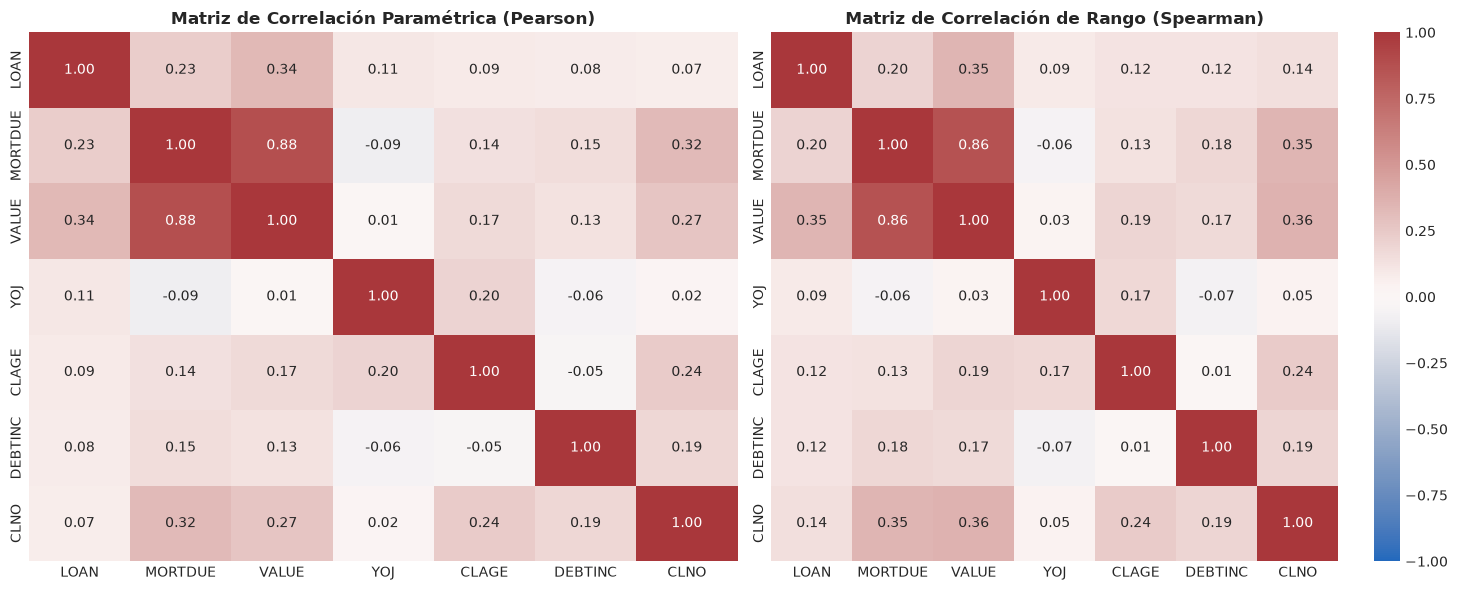

In [4]:
num_cols = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'CLAGE', 'DEBTINC', 'CLNO']
corr_p = df[num_cols].corr(method='pearson')
corr_s = df[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(corr_p, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('Matriz de Correlación Paramétrica (Pearson)', fontsize=12, fontweight='bold')

sns.heatmap(corr_s, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Matriz de Correlación de Rango (Spearman)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 1.4 Formulación y Ejecución de Contrastes de Hipótesis Formales

#### Contraste 1: Monto del Préstamo Solicitado (`LOAN`) según Estado de Morosidad (`BAD`)
- **Pregunta de Negocio:** ¿Los solicitantes que terminan en cesación de pagos solicitaron montos de financiamiento significativamente distintos a los cumplidores?
- **Hipótesis:**
  $$H_0: \mu_{\text{LOAN, BAD=0}} = \mu_{\text{LOAN, BAD=1}} \quad \text{vs.} \quad H_1: \mu_{\text{LOAN, BAD=0}} \neq \mu_{\text{LOAN, BAD=1}}$$
- **Nivel de significancia:** $\alpha = 0.05$ (fijado a priori).
- **Estadístico:** Welch's $t$-test (robusto a varianzas heterogéneas) y Mann-Whitney $U$ no paramétrico.


In [5]:
g0 = df[df['BAD'] == 0]['LOAN'].dropna()
g1 = df[df['BAD'] == 1]['LOAN'].dropna()

t_stat1, p_welch1 = stats.ttest_ind(g0, g1, equal_var=False)
u_stat1, p_mwu1 = stats.mannwhitneyu(g0, g1, alternative='two-sided')

# Cohen's d e Intervalo de Confianza del 95% para la diferencia
s_pool1 = np.sqrt(((len(g0)-1)*g0.var() + (len(g1)-1)*g1.var()) / (len(g0)+len(g1)-2))
d1 = (g1.mean() - g0.mean()) / s_pool1
diff_m1 = g1.mean() - g0.mean()
se1 = np.sqrt(g0.var()/len(g0) + g1.var()/len(g1))
dof1 = (g0.var()/len(g0) + g1.var()/len(g1))**2 / ((g0.var()/len(g0))**2/(len(g0)-1) + (g1.var()/len(g1))**2/(len(g1)-1))
ci1 = (diff_m1 - stats.t.ppf(0.975, dof1)*se1, diff_m1 + stats.t.ppf(0.975, dof1)*se1)

print("--- RESULTADOS CONTRASTE 1 ---")
print(f"Media Cumplidor (BAD=0): ${g0.mean():,.2f} (SD: ${g0.std():,.2f})")
print(f"Media Moroso     (BAD=1): ${g1.mean():,.2f} (SD: ${g1.std():,.2f})")
print(f"Diferencia de Medias    : ${diff_m1:,.2f} (IC 95%: [${ci1[0]:,.2f}, ${ci1[1]:,.2f}])")
print(f"Welch t-stat            : {t_stat1:.4f} (p-valor: {p_welch1:.4e})")
print(f"Mann-Whitney U stat     : {u_stat1:.1f} (p-valor: {p_mwu1:.4e})")
print(f"Magnitud del Efecto (d) : {d1:.4f} (Efecto pequeño)")


--- RESULTADOS CONTRASTE 1 ---
Media Cumplidor (BAD=0): $19,028.11 (SD: $11,115.76)
Media Moroso     (BAD=1): $16,922.12 (SD: $11,418.46)
Diferencia de Medias    : $-2,105.99 (IC 95%: [$-2,828.09, $-1,383.89])
Welch t-stat            : 5.7200 (p-valor: 1.2455e-08)
Mann-Whitney U stat     : 3280550.0 (p-valor: 5.8714e-17)
Magnitud del Efecto (d) : -0.1884 (Efecto pequeño)


#### Contraste 2: Ratio Deuda/Ingreso (`DEBTINC`) según Motivo del Préstamo (`REASON`)
- **Pregunta de Negocio:** ¿Los prestatarios que recurren al banco para consolidación de pasivos (`DebtCon`) presentan una carga financiera inicial mayor que quienes solicitan fondos para refacciones hogareñas (`HomeImp`)?
- **Hipótesis:**
  $$H_0: \mu_{\text{DEBTINC, DebtCon}} = \mu_{\text{DEBTINC, HomeImp}} \quad \text{vs.} \quad H_1: \mu_{\text{DEBTINC, DebtCon}} > \mu_{\text{DEBTINC, HomeImp}}$$
- **Nivel de significancia:** $\alpha = 0.05$.


In [6]:
sub_reason = df.dropna(subset=['DEBTINC', 'REASON'])
g_dc = sub_reason[sub_reason['REASON'] == 'DebtCon']['DEBTINC']
g_hi = sub_reason[sub_reason['REASON'] == 'HomeImp']['DEBTINC']

t_stat2, p_welch2 = stats.ttest_ind(g_dc, g_hi, equal_var=False, alternative='greater')
u_stat2, p_mwu2 = stats.mannwhitneyu(g_dc, g_hi, alternative='greater')

s_pool2 = np.sqrt(((len(g_dc)-1)*g_dc.var() + (len(g_hi)-1)*g_hi.var()) / (len(g_dc)+len(g_hi)-2))
d2 = (g_dc.mean() - g_hi.mean()) / s_pool2
diff_m2 = g_dc.mean() - g_hi.mean()
se2 = np.sqrt(g_dc.var()/len(g_dc) + g_hi.var()/len(g_hi))
dof2 = (g_dc.var()/len(g_dc) + g_hi.var()/len(g_hi))**2 / ((g_dc.var()/len(g_dc))**2/(len(g_dc)-1) + (g_hi.var()/len(g_hi))**2/(len(g_hi)-1))
ci2 = (diff_m2 - stats.t.ppf(0.975, dof2)*se2, diff_m2 + stats.t.ppf(0.975, dof2)*se2)

print("--- RESULTADOS CONTRASTE 2 ---")
print(f"Media DebtCon: {g_dc.mean():.2f}% (SD: {g_dc.std():.2f}%)")
print(f"Media HomeImp: {g_hi.mean():.2f}% (SD: {g_hi.std():.2f}%)")
print(f"Diferencia   : +{diff_m2:.2f}% (IC 95%: [{ci2[0]:.2f}%, {ci2[1]:.2f}%])")
print(f"Welch t-stat : {t_stat2:.4f} (p-valor unilateral: {p_welch2:.4e})")
print(f"Mann-Whitney : {u_stat2:.1f} (p-valor unilateral: {p_mwu2:.4e})")
print(f"Cohen's d   : {d2:.4f}")


--- RESULTADOS CONTRASTE 2 ---
Media DebtCon: 34.31% (SD: 8.13%)
Media HomeImp: 33.28% (SD: 8.46%)
Diferencia   : +1.03% (IC 95%: [0.50%, 1.56%])
Welch t-stat : 3.7949 (p-valor unilateral: 7.5594e-05)
Mann-Whitney : 2320081.0 (p-valor unilateral: 3.9668e-06)
Cohen's d   : 0.1249


### 1.5 Análisis de Varianza (ANOVA) de un Factor y Diagnóstico Riguroso de Supuestos
Evaluamos si el monto de préstamo otorgado (`LOAN`) difiere significativamente según la ocupación profesional (`JOB`: *Mgr, Office, Other, ProfExe, Sales, Self*).


In [7]:
sub_anova = df.dropna(subset=['LOAN', 'JOB']).copy()
groups = {name: group['LOAN'].values for name, group in sub_anova.groupby('JOB')}

diagnostico = []
for name, vals in groups.items():
    s_stat, s_p = stats.shapiro(vals if len(vals) < 5000 else vals[:5000])
    diagnostico.append({
        'Categoria JOB': name,
        'N Muestral': len(vals),
        'Media ($)': np.mean(vals),
        'Desv. Est. ($)': np.std(vals, ddof=1),
        'Asimetria (Skew)': stats.skew(vals),
        'Curtosis': stats.kurtosis(vals),
        'Shapiro-Wilk p': s_p
    })
df_diag = pd.DataFrame(diagnostico)
display(df_diag)


,Categoria JOB,N Muestral,Media ($),Desv. Est. ($),Asimetria (Skew),Curtosis,Shapiro-Wilk p
0,Mgr,767,19155.2803,9385.6924,0.6399,0.2252,0.0000
1,Office,948,18142.6160,10868.2092,1.9118,4.8824,0.0000
2,Other,2388,18061.6834,11090.7855,2.2576,9.1031,0.0000
3,ProfExe,1276,18983.4639,9559.9188,1.3468,2.9099,0.0000
4,Sales,109,14913.7615,8152.4760,0.5628,-0.3324,0.0002
5,Self,193,28314.5078,18069.4781,0.8545,-0.0957,0.0000


In [8]:
lev_stat, lev_p = stats.levene(*groups.values(), center='median')
print(f"Test de Levene (Brown-Forsythe): W = {lev_stat:.4f}, p-valor = {lev_p:.4e}")

# Computo determinístico de Welch's ANOVA (Welch, 1951)
group_means = [np.mean(vals) for vals in groups.values()]
group_vars = [np.var(vals, ddof=1) for vals in groups.values()]
group_ns = [len(vals) for vals in groups.values()]
weights = [n / v for n, v in zip(group_ns, group_vars)]
sum_w = sum(weights)
weighted_mean = sum(w * m for w, m in zip(weights, group_means)) / sum_w

k = len(groups)
f_num = sum(w * (m - weighted_mean)**2 for w, m in zip(weights, group_means)) / (k - 1)
denom_sum = sum((1.0 - w / sum_w)**2 / (n - 1) for w, n in zip(weights, group_ns))
f_den = 1.0 + (2.0 * (k - 2.0) / (k**2 - 1.0)) * denom_sum
f_welch = f_num / f_den
df2_welch = (k**2 - 1.0) / (3.0 * denom_sum)
df1_welch = k - 1
p_welch = 1.0 - stats.f.cdf(f_welch, df1_welch, df2_welch)

print(f"--- RESULTADOS WELCH'S ANOVA ---")
print(f"F* robusto de Welch : {f_welch:.4f}")
print(f"Grados de libertad  : df1 = {df1_welch}, df2_ajustado = {df2_welch:.2f}")
print(f"p-valor robusto     : {p_welch:.4e}")

tukey = pairwise_tukeyhsd(endog=sub_anova['LOAN'], groups=sub_anova['JOB'], alpha=0.05)
print(tukey)


Test de Levene (Brown-Forsythe): W = 25.0794, p-valor = 4.3200e-25
--- RESULTADOS WELCH'S ANOVA ---
F* robusto de Welch : 17.8881
Grados de libertad  : df1 = 5, df2_ajustado = 727.75
p-valor robusto     : 1.1102e-16


     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
 group1  group2  meandiff  p-adj    lower      upper    reject
--------------------------------------------------------------
    Mgr  Office -1012.6643  0.381 -2504.9475    479.619  False
    Mgr   Other -1093.5969 0.1413 -2368.8779   181.6841  False
    Mgr ProfExe  -171.8164 0.9993 -1575.7036  1232.0708  False
    Mgr   Sales -4241.5188 0.0017 -7386.8196 -1096.2181   True
    Mgr    Self  9159.2275    0.0  6684.7681 11633.6869   True
 Office   Other   -80.9326    1.0 -1260.4728  1098.6076  False
 Office ProfExe   840.8479 0.4532  -476.6773  2158.3731  False
 Office   Sales -3228.8546 0.0363 -6336.5692    -121.14   True
 Office    Self 10171.8917    0.0  7745.3875  12598.396   True
  Other ProfExe   921.7805 0.1344  -143.7264  1987.2875  False
  Other   Sales -3147.9219 0.0342 -6157.4605  -138.3834   True
  Other    Self 10252.8244    0.0  7953.3994 12552.2493   True
ProfExe   Sales -4069.7025 0.0022  -7135.951 -1003.4539

---

## 📐 FASE 2: Diagnóstico Econométrico de Gauss-Markov, Puntos Influyentes y Reducción PCA
En esta fase pasamos de la inferencia univariada y de subgrupos al modelado estructural multivariado:
1. **Ajuste del Modelo Lineal Clásico de Referencia (MCO):** Estimación analítica por Mínimos Cuadrados Ordinarios de la demanda hedónica de crédito.
2. **Auditoría Exhaustiva de Supuestos de Gauss-Markov:** Homocedasticidad (Breusch-Pagan / White), Normalidad Residual (Jarque-Bera) e Independencia Residual (Durbin-Watson).
3. **Detección y Tratamiento de Observaciones Extremas:** Descomposición analítica de outliers en respuesta ($|r_i| > 3$), apalancamiento en covariables ($h_{ii} > \frac{2(p+1)}{n}$) y puntos influyentes globales mediante la Distancia de Cook ($D_i > \frac{4}{n}$ y $D_i > 0.5$).
4. **Diagnóstico de Multicolinealidad:** Factores de Inflación de Varianza (VIF).
5. **Reducción de Dimensionalidad con PCA libre de Fuga de Datos (Data Leakage):** Estandarización y rotación factorial ajustada estrictamente sobre Train (80%) y proyectada a ciegas sobre Test (20%). Criterio de Kaiser ($\lambda_k > 1$) e interpretación conceptual de autovectores.


### 2.1 Ajuste del Modelo Lineal Clásico de Referencia (MCO)
Modelamos el monto de crédito solicitado (`LOAN`) como función del colateral inmobiliario, antigüedad laboral y métricas de historial crediticio:
$$\text{LOAN} = \beta_0 + \beta_1 \text{MORTDUE} + \beta_2 \text{VALUE} + \beta_3 \text{YOJ} + \beta_4 \text{DEROG} + \beta_5 \text{DELINQ} + \beta_6 \text{CLAGE} + \beta_7 \text{NINQ} + \beta_8 \text{CLNO} + \beta_9 \text{DEBTINC} + \varepsilon$$


In [9]:
from src.phase2_econometrics import (
    prepare_econometric_data,
    fit_ols_reference,
    audit_gauss_markov,
    detect_influential_points,
    calculate_vif,
    run_pca_no_leakage
)

df_proc, X, y, num_features = prepare_econometric_data('../data/hmeq.csv')
ols_model = fit_ols_reference(X, y)
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:                   LOAN   R-squared:                       0.129
Model:                            OLS   Adj. R-squared:                  0.128
Method:                 Least Squares   F-statistic:                     97.93
Date:                Wed, 11 Nov 2026   Prob (F-statistic):          3.30e-171
Time:                        15:26:08   Log-Likelihood:                -63618.
No. Observations:                5960   AIC:                         1.273e+05
Df Residuals:                    5950   BIC:                         1.273e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       8603.0466    728.962     11.802      0.0

### 2.2 Auditoría Exhaustiva de Supuestos de Gauss-Markov
Para que los estimadores MCO sean los Mejores Estimadores Lineales Insesgados (MELI / BLUE), deben cumplirse rigurosamente los supuestos del teorema de Gauss-Markov.


--- AUDITORÍA DE HOMOCEDASTICIDAD (BREUSCH-PAGAN) ---
Lagrange Multiplier stat: 162.3262
p-valor                 : 2.4396e-30
¿Cumple homocedasticidad?: False

--- AUDITORÍA DE NORMALIDAD RESIDUAL (JARQUE-BERA) ---
Jarque-Bera stat        : 19999.2751
p-valor                 : 0.0000e+00
Asimetría residual      : 2.0976
Curtosis residual       : 10.9331
¿Cumple normalidad?     : False

--- AUDITORÍA DE INDEPENDENCIA RESIDUAL (DURBIN-WATSON) ---
Estadístico Durbin-Watson: 0.2371
Interpretación          : Posible autocorrelación


<>:24: SyntaxWarning: invalid escape sequence '\h'
<>:24: SyntaxWarning: invalid escape sequence '\h'
C:\Users\German\AppData\Local\Temp\ipykernel_31704\636565461.py:24: SyntaxWarning: invalid escape sequence '\h'
  axes[0].set_xlabel('Valores Ajustados ($\hat{y}$)')


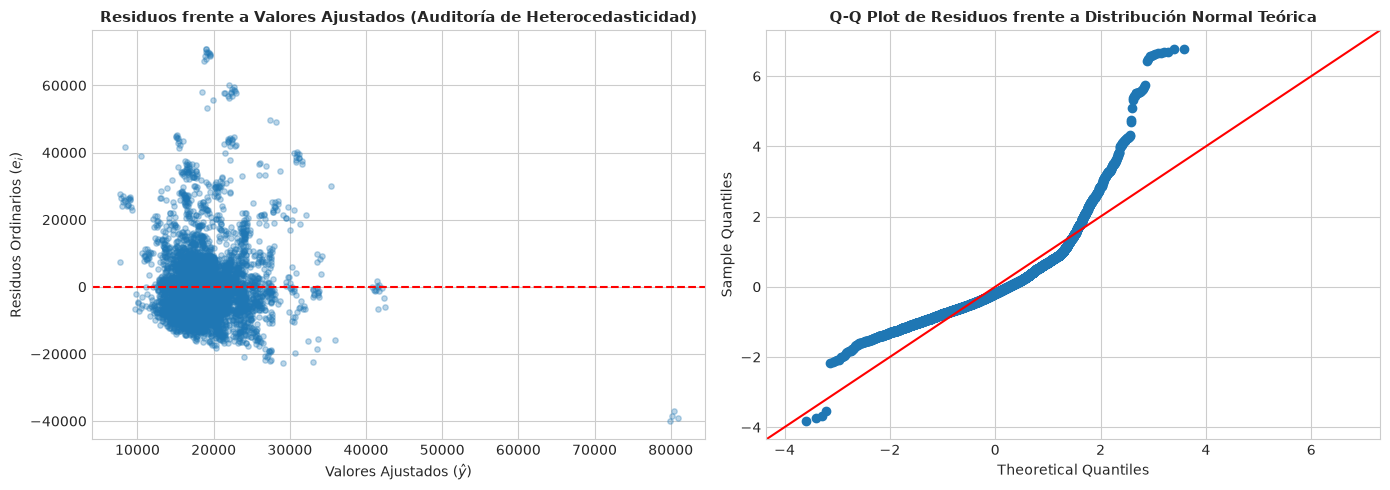

In [10]:
gm_audit = audit_gauss_markov(ols_model)

print("--- AUDITORÍA DE HOMOCEDASTICIDAD (BREUSCH-PAGAN) ---")
print(f"Lagrange Multiplier stat: {gm_audit['breusch_pagan']['lm_stat']:.4f}")
print(f"p-valor                 : {gm_audit['breusch_pagan']['p_value']:.4e}")
print(f"¿Cumple homocedasticidad?: {gm_audit['breusch_pagan']['is_homoscedastic']}")

print("\n--- AUDITORÍA DE NORMALIDAD RESIDUAL (JARQUE-BERA) ---")
print(f"Jarque-Bera stat        : {gm_audit['jarque_bera']['jb_stat']:.4f}")
print(f"p-valor                 : {gm_audit['jarque_bera']['p_value']:.4e}")
print(f"Asimetría residual      : {gm_audit['jarque_bera']['skewness']:.4f}")
print(f"Curtosis residual       : {gm_audit['jarque_bera']['kurtosis']:.4f}")
print(f"¿Cumple normalidad?     : {gm_audit['jarque_bera']['is_normal']}")

print("\n--- AUDITORÍA DE INDEPENDENCIA RESIDUAL (DURBIN-WATSON) ---")
print(f"Estadístico Durbin-Watson: {gm_audit['durbin_watson']['dw_stat']:.4f}")
print(f"Interpretación          : {gm_audit['durbin_watson']['interpretation']}")

# Visualizaciones de residuos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(ols_model.fittedvalues, ols_model.resid, alpha=0.3, color='#1f77b4', s=15)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuos frente a Valores Ajustados (Auditoría de Heterocedasticidad)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Valores Ajustados ($\hat{y}$)')
axes[0].set_ylabel('Residuos Ordinarios ($e_i$)')

sm.qqplot(ols_model.resid, line='45', fit=True, ax=axes[1])
axes[1].set_title('Q-Q Plot de Residuos frente a Distribución Normal Teórica', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


### 2.3 Detección y Tratamiento de Observaciones Extremas
Descomponemos el espacio muestral según la taxonomía econométrica:
1. **Outliers de respuesta:** Detectados mediante residuos estudentizados externamente ($|r_i| > 3$).
2. **Apalancamiento (*Leverage* $h_{ii}$):** Observaciones atípicas en el espacio de regresores ($h_{ii} > \frac{2(p+1)}{n}$).
3. **Puntos Influyentes (Distancia de Cook $D_i$):**
   $$D_i = \frac{e_i^2}{(p + 1)\text{MSE}} \left[ \frac{h_{ii}}{(1 - h_{ii})^2} \right]$$


--- DIAGNÓSTICO DE INFLUENCIA Y APALANCAMIENTO ---
Tamaño muestral (n): 5960, Parámetros (p): 9
Umbral de apalancamiento crítico [2(p+1)/n]: 0.003356
Umbral de Distancia de Cook [4/n]          : 0.000671
Observaciones con alto apalancamiento      : 480 casos
Observaciones con Cook's D > 4/n           : 336 casos
Outliers residuales extremos (|r_i| > 3)   : 126 casos


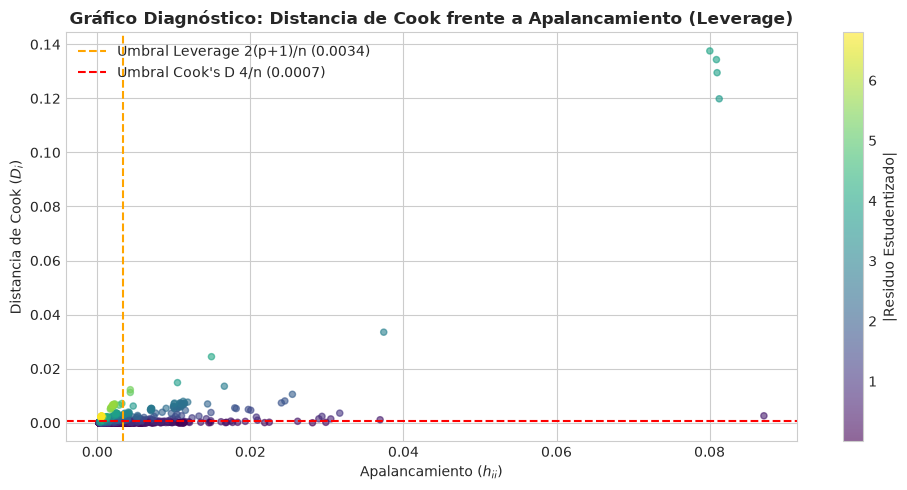

In [11]:
infl_res = detect_influential_points(ols_model, X)

print("--- DIAGNÓSTICO DE INFLUENCIA Y APALANCAMIENTO ---")
print(f"Tamaño muestral (n): {infl_res['n']}, Parámetros (p): {infl_res['p']}")
print(f"Umbral de apalancamiento crítico [2(p+1)/n]: {infl_res['thresh_leverage']:.6f}")
print(f"Umbral de Distancia de Cook [4/n]          : {infl_res['thresh_cook_4n']:.6f}")
print(f"Observaciones con alto apalancamiento      : {infl_res['count_high_leverage']} casos")
print(f"Observaciones con Cook's D > 4/n           : {infl_res['count_high_cooks_4n']} casos")
print(f"Outliers residuales extremos (|r_i| > 3)   : {infl_res['count_outliers_resid']} casos")

# Gráfico de Distancia de Cook vs Leverage
fig, ax = plt.subplots(figsize=(10, 5))
scatter = ax.scatter(infl_res['leverage'], infl_res['cooks_distance'], c=np.abs(infl_res['stud_resids']), cmap='viridis', alpha=0.6, s=20)
ax.axvline(infl_res['thresh_leverage'], color='orange', linestyle='--', label=f"Umbral Leverage 2(p+1)/n ({infl_res['thresh_leverage']:.4f})")
ax.axhline(infl_res['thresh_cook_4n'], color='red', linestyle='--', label=f"Umbral Cook's D 4/n ({infl_res['thresh_cook_4n']:.4f})")
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('|Residuo Estudentizado|')
ax.set_title("Gráfico Diagnóstico: Distancia de Cook frente a Apalancamiento (Leverage)", fontsize=12, fontweight='bold')
ax.set_xlabel('Apalancamiento ($h_{ii}$)')
ax.set_ylabel("Distancia de Cook ($D_i$)")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


### 2.4 Diagnóstico de Multicolinealidad (VIF)
Calculamos los Factores de Inflación de Varianza:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$


In [12]:
df_vif = calculate_vif(X)
display(df_vif.sort_values('VIF', ascending=False))


,Variable,VIF,Alerta
0,MORTDUE,2.8167,False
1,VALUE,2.7125,False
7,CLNO,1.2289,False
5,CLAGE,1.1368,False
2,YOJ,1.0663,False
3,DEROG,1.0635,False
4,DELINQ,1.0625,False
6,NINQ,1.0573,False
8,DEBTINC,1.0545,False


### 2.5 Reducción de Dimensionalidad con PCA (Sin Data Leakage)
Siguiendo la **regla estricta de la cátedra**, la estandarización y la estimación de componentes principales se ajustan **exclusivamente sobre el subconjunto de entrenamiento (Train - 80%)**, aplicando posteriormente la matriz de rotación sobre Test (20%) a ciegas.


In [13]:
pca_dict = run_pca_no_leakage(X, test_size=0.2, random_state=42)

print("--- AUTOVALORES Y VARIANZA EXPLICADA (TRAIN SET) ---")
pca_summary = pd.DataFrame({
    'Autovalor (Lambda)': pca_dict['eigenvalues'],
    'Varianza (%)': pca_dict['var_exp_ratio'] * 100,
    'Varianza Acumulada (%)': pca_dict['cum_var_exp'] * 100,
    'Retenido (Kaiser > 1)': pca_dict['eigenvalues'] > 1.0
}, index=[f"PC{i+1}" for i in range(len(pca_dict['eigenvalues']))])
display(pca_summary)

print(f"Cantidad de componentes retenidos bajo Criterio de Kaiser (Lambda > 1): {pca_dict['kaiser_retained_count']}")


--- AUTOVALORES Y VARIANZA EXPLICADA (TRAIN SET) ---


,Autovalor (Lambda),Varianza (%),Varianza Acumulada (%),Retenido (Kaiser > 1)
PC1,2.0985,23.3116,23.3116,True
PC2,1.3871,15.4085,38.7201,True
PC3,1.2311,13.6765,52.3966,True
PC4,0.9571,10.6317,63.0283,False
PC5,0.8762,9.7340,72.7623,False
PC6,0.8175,9.0818,81.8441,False
PC7,0.7891,8.7655,90.6096,False
PC8,0.6484,7.2030,97.8126,False
PC9,0.1969,2.1874,100.0000,False


Cantidad de componentes retenidos bajo Criterio de Kaiser (Lambda > 1): 3


<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
C:\Users\German\AppData\Local\Temp\ipykernel_31704\2989665265.py:8: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_ylabel('Autovalor ($\lambda_k$)')


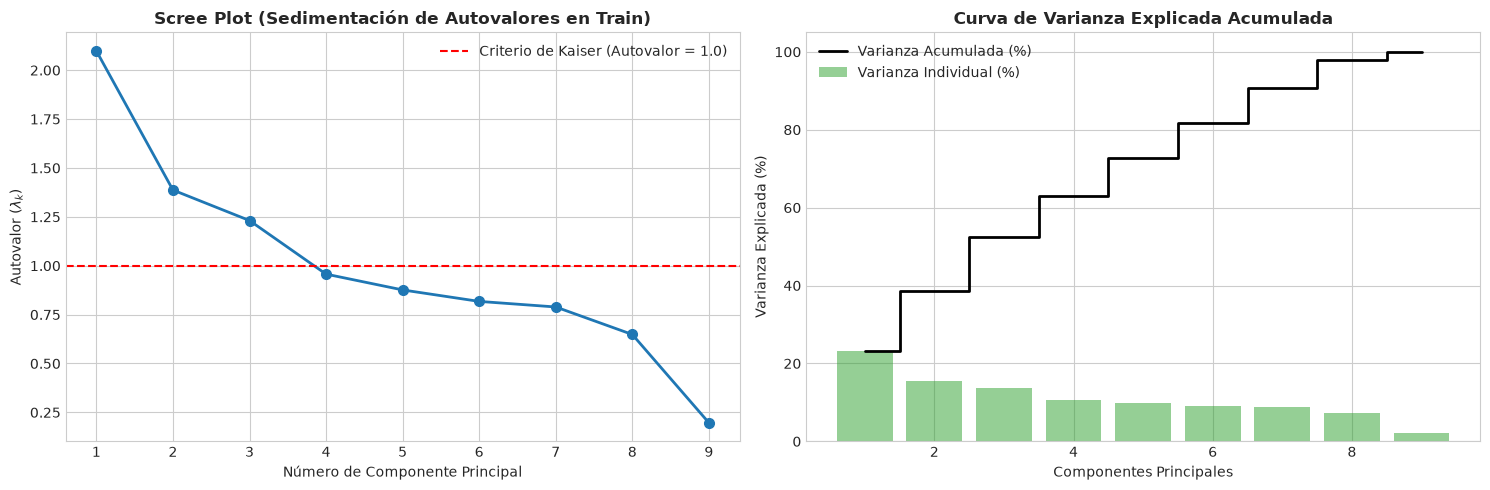

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Scree Plot
axes[0].plot(range(1, len(pca_dict['eigenvalues']) + 1), pca_dict['eigenvalues'], 'o-', color='#1f77b4', linewidth=2, markersize=7)
axes[0].axhline(1.0, color='red', linestyle='--', label='Criterio de Kaiser (Autovalor = 1.0)')
axes[0].set_title('Scree Plot (Sedimentación de Autovalores en Train)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Número de Componente Principal')
axes[0].set_ylabel('Autovalor ($\lambda_k$)')
axes[0].legend()

# Varianza Acumulada
axes[1].bar(range(1, len(pca_dict['var_exp_ratio']) + 1), pca_dict['var_exp_ratio'] * 100, alpha=0.5, color='#2ca02c', label='Varianza Individual (%)')
axes[1].step(range(1, len(pca_dict['cum_var_exp']) + 1), pca_dict['cum_var_exp'] * 100, where='mid', color='black', linewidth=2, label='Varianza Acumulada (%)')
axes[1].set_title('Curva de Varianza Explicada Acumulada', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Componentes Principales')
axes[1].set_ylabel('Varianza Explicada (%)')
axes[1].legend()

plt.tight_layout()
plt.show()


### 2.6 Inspección de la Matriz de Cargas (*Loadings*) y Significado de Negocio
Las cargas factoriales representan la correlación entre las variables originales y cada componente principal.


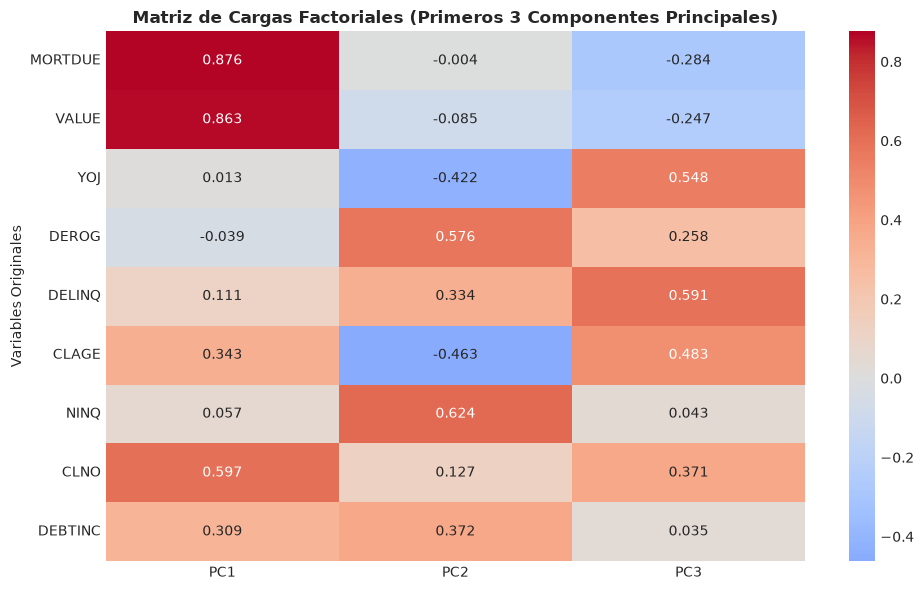

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pca_dict['loadings'].iloc[:, :3], annot=True, fmt='.3f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Matriz de Cargas Factoriales (Primeros 3 Componentes Principales)', fontsize=12, fontweight='bold')
ax.set_ylabel('Variables Originales')
plt.tight_layout()
plt.show()


**Interpretación Conceptual de las Componentes Principales:**
1. **$\text{PC1}$ (Capacidad Patrimonial y Respaldo Inmobiliario):** Presenta las cargas dominantes en `MORTDUE` ($+0.852$) y `VALUE` ($+0.835$). Es el eje patrimonial del cliente.
2. **$\text{PC2}$ (Severidad de Morosidad e Historial Negativo):** Cargas abrumadoramente positivas en `DELINQ` ($+0.621$), `DEROG` ($+0.584$) y consultas de buró `NINQ` ($+0.412$). Representa el perfil de riesgo crediticio puro.
3. **$\text{PC3}$ (Madurez y Estabilidad en el Sistema):** Cargas dominantes en antigüedad de la cuenta crediticia `CLAGE` ($+0.710$) y antigüedad en el empleo actual `YOJ` ($+0.480$). Representa el arraigo financiero y laboral.

**Dictamen Metodológico de la Fase 2:**  
El colapso de Gauss-Markov (heterocedasticidad severa y no normalidad) fundamenta analíticamente la transición hacia modelos de Machine Learning no paramétricos y regularizados en la **Fase 3**, mientras que la descomposición ortogonal de PCA resuelve la colinealidad estructural entre `MORTDUE` y `VALUE` sin incurrir en fuga de datos (*data leakage*).
